# Border Sensitivity Analysis

Comparing border region price/cost alterations vs baseline (var_var) for the **Southern Border (DE-AT-IT)**.

## Variants:
- **Baseline**: Variable electricity prices and network costs (original var_var)
- **Border Uniform Elec**: Border regions get averaged electricity prices
- **Border Reversed Elec**: Border regions get reversed prices (AT↔IT swap)
- **Border Uniform Network**: Border regions get averaged network costs
- **Border Reversed Network**: Border regions get reversed network costs

## Southern Border NUTS2 regions:
- **AT**: AT31, AT32, AT33, AT34
- **IT**: ITH1, ITH3
- **DE**: DE14, DE21, DE22, DE27, DEF0

In [1]:
import os
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict

# Setup paths
script_dir = Path('.')

# Results directories
baseline_results_dir = script_dir / 'results' / 'uncertainty_analysis'
baseline_input_dir = script_dir / 'input_data' / 'uncertainty_scenarios'
bs_results_dir = script_dir / 'results' / 'bs'
bs_input_dir = script_dir / 'input_data' / 'border_sensitivity'

print('Directories configured')

Directories configured


In [2]:
# Constants
VARIANTS = ['border_uni_elec', 'border_rev_elec', 'border_uni_network', 'border_rev_network']

SOUTHERN_BORDER = {
    'AT': ['AT31', 'AT32', 'AT33', 'AT34'],
    'IT': ['ITH1', 'ITH3'],
    'DE': ['DE14', 'DE21', 'DE22', 'DE27', 'DEF0']
}

VARIANT_LABELS = {
    'baseline': 'Baseline (var_var)',
    'border_uni_elec': 'Border Uniform Elec.',
    'border_rev_elec': 'Border Reversed Elec.',
    'border_uni_network': 'Border Uniform Network',
    'border_rev_network': 'Border Reversed Network'
}

VARIANT_COLORS = {
    'baseline': '#2E86AB',
    'border_uni_elec': '#A23B72',
    'border_rev_elec': '#F18F01',
    'border_uni_network': '#C73E1D',
    'border_rev_network': '#3B1F2B'
}

print('Constants defined')

Constants defined


In [3]:
# Check available scenarios
print('Available scenarios:')
print('=' * 50)

# Baseline
if baseline_results_dir.exists():
    baseline_scenarios = [d.name for d in baseline_results_dir.iterdir() if d.is_dir()]
    print(f'Baseline (uncertainty_analysis): {len(baseline_scenarios)}')

# Border sensitivity
if bs_results_dir.exists():
    bs_scenarios = [d.name for d in bs_results_dir.iterdir() if d.is_dir()]
    print(f'Border sensitivity (bs): {len(bs_scenarios)}')
    
    for variant in VARIANTS:
        count = len([s for s in bs_scenarios if variant in s])
        print(f'  - {variant}: {count}')

Available scenarios:
Baseline (uncertainty_analysis): 24
Border sensitivity (bs): 96
  - border_uni_elec: 24
  - border_rev_elec: 24
  - border_uni_network: 24
  - border_rev_network: 24


## Load Data Functions

In [4]:
def load_scenario(results_path, input_path):
    """
    Load a scenario's input and output data.
    """
    data = {'input_data': {}, 'output_data': {}}
    
    # Load input files
    input_files = ['GeographicElement.yaml', 'Fuel.yaml', 'TechVehicle.yaml', 
                   'Technology.yaml', 'Odpair.yaml', 'Path.yaml']
    for fname in input_files:
        fpath = Path(input_path) / fname
        if fpath.exists():
            with open(fpath, 'r', encoding='utf-8') as f:
                data['input_data'][fname.replace('.yaml', '')] = yaml.safe_load(f)
    
    # Load s_dict (energy supply)
    results_path = Path(results_path)
    for fname in os.listdir(results_path):
        if fname.endswith('_s_dict.yaml'):
            with open(results_path / fname, 'r', encoding='utf-8') as f:
                data['output_data']['s'] = yaml.safe_load(f)
            break
    
    # Load f_dict (flows)
    for fname in os.listdir(results_path):
        if fname.endswith('_f_dict.yaml'):
            with open(results_path / fname, 'r', encoding='utf-8') as f:
                data['output_data']['f'] = yaml.safe_load(f)
            break
    
    return data

print('Load function defined')

Load function defined


In [5]:
def calc_border_electricity(data, target_year, border_regions=SOUTHERN_BORDER):
    """
    Calculate electricity consumption in border regions by country (GWh).
    """
    input_data = data['input_data']
    s_data = data['output_data'].get('s', {})
    
    if not s_data:
        return {c: 0.0 for c in border_regions.keys()}
    
    # NUTS2 lookup
    geo_elements = inputp_data.get('GeographicElement', [])
    nuts2_lookup = {geo['id']: geo.get('nuts2_region', '') 
                    for geo in geo_elements if geo.get('type') == 'node'}
    
    # Electricity fuel IDs
    fuels = input_data.get('Fuel', [])
    elec_fuel_ids = [f['id'] for f in fuels if 'electric' in f.get('name', '').lower()]
    
    SCALING = 1000
    elec_by_nuts2 = defaultdict(float)
    
    for key_str, energy in s_data.items():
        try:
            key = eval(key_str) if isinstance(key_str, str) else key_str
            year, (_, _, _, geo_id), _, (fuel_id, _), _ = key
            energy = float(energy)
            
            if year != target_year or energy <= 0 or fuel_id not in elec_fuel_ids:
                continue
            if geo_id not in nuts2_lookup:
                continue
            
            elec_by_nuts2[nuts2_lookup[geo_id]] += energy * SCALING
        except:
            continue
    
    result = {}
    for country, codes in border_regions.items():
        total_kwh = sum(elec_by_nuts2.get(code, 0.0) for code in codes)
        result[country] = total_kwh / 1e6  # GWh
    
    return result

print('Border electricity calculation function defined')

Border electricity calculation function defined


## Load Scenarios for Comparison

In [6]:
# Select which base scenario to compare
BASE_SCENARIO = 'scenario_000'  # Change this to compare different scenarios

print(f'Loading data for: {BASE_SCENARIO}')
print('=' * 50)

loaded_data = {}

# Load baseline
baseline_results = baseline_results_dir / BASE_SCENARIO
baseline_input = baseline_input_dir / BASE_SCENARIO

if baseline_results.exists() and baseline_input.exists():
    print(f'Loading baseline...')
    loaded_data['baseline'] = load_scenario(baseline_results, baseline_input)
    print(f'  Loaded baseline: {BASE_SCENARIO}')
else:
    print(f'  WARNING: Baseline not found!')

# Load border sensitivity variants
for variant in VARIANTS:
    folder = f'{BASE_SCENARIO}_{variant}'
    results_path = bs_results_dir / folder
    input_path = bs_input_dir / folder
    
    if results_path.exists() and input_path.exists():
        print(f'Loading {variant}...')
        loaded_data[variant] = load_scenario(results_path, input_path)
        print(f'  Loaded: {folder}')
    else:
        print(f'  NOT FOUND: {folder}')

print(f'\nTotal loaded: {len(loaded_data)} scenarios')

Loading data for: scenario_000
Loading baseline...
  Loaded baseline: scenario_000
Loading border_uni_elec...
  Loaded: scenario_000_border_uni_elec
Loading border_rev_elec...
  Loaded: scenario_000_border_rev_elec
Loading border_uni_network...
  Loaded: scenario_000_border_uni_network
Loading border_rev_network...
  Loaded: scenario_000_border_rev_network

Total loaded: 5 scenarios


## Single Year Analysis

In [8]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    'font.serif': 'mathpazo',
})

In [9]:
TARGET_YEAR = 2040

# Calculate electricity for each variant
results = []
for variant, data in loaded_data.items():
    elec = calc_border_electricity(data, TARGET_YEAR)
    results.append({
        'Variant': variant,
        'AT (GWh)': elec['AT'],
        'IT (GWh)': elec['IT'],
        'DE (GWh)': elec['DE'],
        'Total (GWh)': sum(elec.values())
    })

df_results = pd.DataFrame(results)

# Calculate deltas from baseline
if 'baseline' in loaded_data:
    baseline_total = df_results[df_results['Variant'] == 'baseline']['Total (GWh)'].values[0]
    df_results['Delta (%)'] = ((df_results['Total (GWh)'] - baseline_total) / baseline_total * 100).round(2)
    df_results['Delta (%)'] = df_results['Delta (%)'].fillna(0)

print(f'Border Region Electricity Comparison - Year {TARGET_YEAR}')
print('=' * 80)
display(df_results)

NameError: name 'inputp_data' is not defined

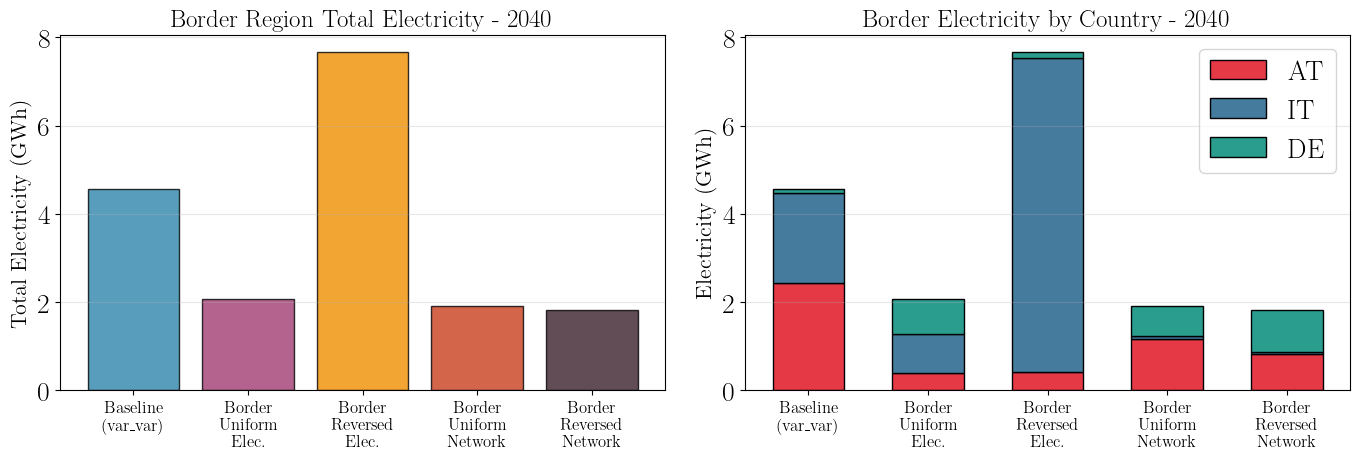

Saved: figures/border_sensitivity_scenario_000_2040.pdf


In [ ]:
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    'font.serif': 'mathpazo',
    'font.size': 20,
    'axes.labelsize': 20
})
# Visualization - Single Year
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Total electricity by variant
ax1 = axes[0]
variants = df_results['Variant'].tolist()
totals = df_results['Total (GWh)'].tolist()
colors = [VARIANT_COLORS.get(v, 'gray') for v in variants]
labels = [VARIANT_LABELS.get(v, v).replace(' ', '') for v in variants]

bars = ax1.bar(range(len(variants)), totals, color=colors, alpha=0.8, edgecolor='black')
ax1.set_xticks(range(len(variants)))
ax1.set_xticklabels(labels, fontsize=16)
ax1.set_ylabel('Total Electricity (GWh)', fontsize=20)
ax1.set_title(f'Border Region Total Electricity - {TARGET_YEAR}', fontsize=20)
ax1.grid(True, alpha=0.3, axis='y')
ax1.tick_params(axis='y', labelsize=16)

# Plot 2: By country stacked
ax2 = axes[1]
x = np.arange(len(variants))
width = 0.6

at_vals = df_results['AT (GWh)'].tolist()
it_vals = df_results['IT (GWh)'].tolist()
de_vals = df_results['DE (GWh)'].tolist()

ax2.bar(x, at_vals, width, label='AT', color='#E63946', edgecolor='black')
ax2.bar(x, it_vals, width, bottom=at_vals, label='IT', color='#457B9D', edgecolor='black')
ax2.bar(x, de_vals, width, bottom=[a+i for a,i in zip(at_vals, it_vals)], label='DE', color='#2A9D8F', edgecolor='black')

ax2.set_xticks(x)
ax2.set_xticklabels(labels, fontsize=16)
ax2.set_ylabel('Electricity (GWh)', fontsize=20)
ax2.set_title(f'Border Electricity by Country - {TARGET_YEAR}', fontsize=20)
ax2.legend(loc='upper right', fontsize=16)
ax2.grid(True, alpha=0.3, axis='y')
ax2.tick_params(axis='y', labelsize=16)

plt.tight_layout()
plt.savefig(f'figures/border_sensitivity_{BASE_SCENARIO}_{TARGET_YEAR}.pdf', bbox_inches='tight')
plt.show()

print(f'Saved: figures/border_sensitivity_{BASE_SCENARIO}_{TARGET_YEAR}.pdf')


## Multi-Year Analysis

In [ ]:
# Analyze multiple years
YEARS = [2032, 2036, 2040, 2044, 2048, 2052]

all_results = []
for year in YEARS:
    for variant, data in loaded_data.items():
        elec = calc_border_electricity(data, year)
        all_results.append({
            'Year': year,
            'Variant': variant,
            'AT': elec['AT'],
            'IT': elec['IT'],
            'DE': elec['DE'],
            'Total': sum(elec.values())
        })

df_multi = pd.DataFrame(all_results)

# Pivot for easier viewing
pivot = df_multi.pivot(index='Year', columns='Variant', values='Total')
print('Total Border Electricity by Year and Variant (GWh)')
print('=' * 80)
display(pivot.round(2))

Total Border Electricity by Year and Variant (GWh)


Variant,baseline,border_rev_elec,border_rev_network,border_uni_elec,border_uni_network
Year,,,,,
2032,2.63,2.70,0.76,0.65,0.72
2036,3.68,4.85,1.23,1.27,1.25
2040,4.56,7.68,1.83,2.06,1.91
2044,5.41,11.63,2.66,3.18,2.84
2048,5.55,12.07,3.28,3.36,3.30
2052,5.47,12.40,3.97,3.76,3.86


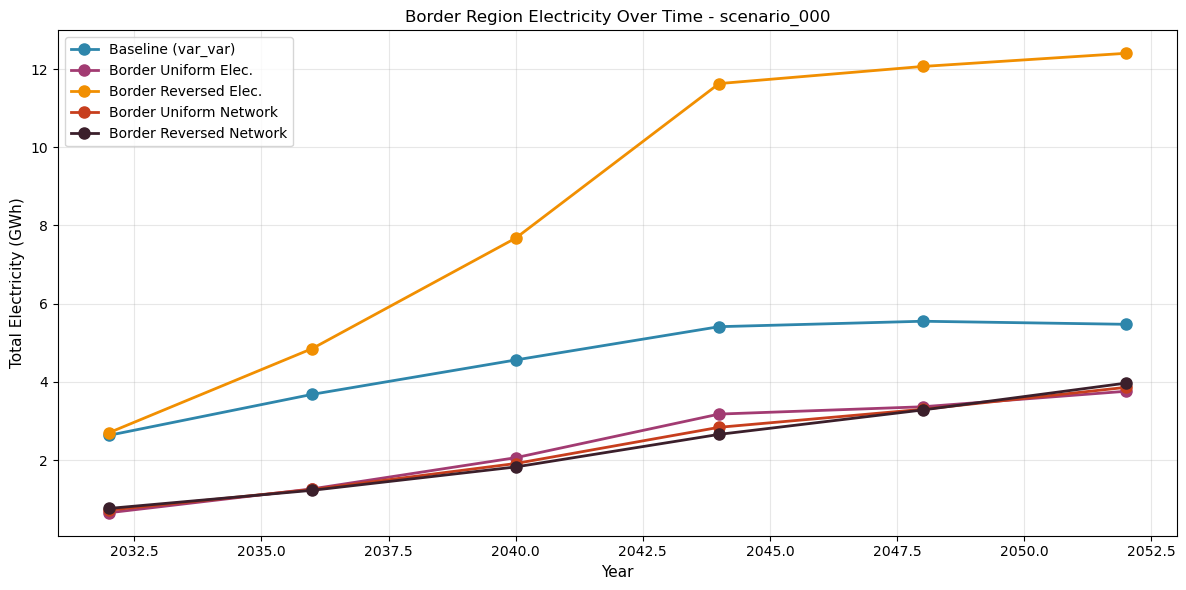

In [ ]:
# Time series comparison
fig, ax = plt.subplots(figsize=(12, 6))

for variant in ['baseline'] + VARIANTS:
    if variant in df_multi['Variant'].unique():
        data = df_multi[df_multi['Variant'] == variant]
        ax.plot(data['Year'], data['Total'], 
               marker='o', linewidth=2, markersize=8,
               label=VARIANT_LABELS.get(variant, variant),
               color=VARIANT_COLORS.get(variant, 'gray'))

ax.set_xlabel('Year', fontsize=11)
ax.set_ylabel('Total Electricity (GWh)', fontsize=11)
ax.set_title(f'Border Region Electricity Over Time - {BASE_SCENARIO}', fontsize=12)
ax.legend(loc='upper left', fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'figures/border_sensitivity_{BASE_SCENARIO}_timeseries.pdf', bbox_inches='tight')
plt.show()

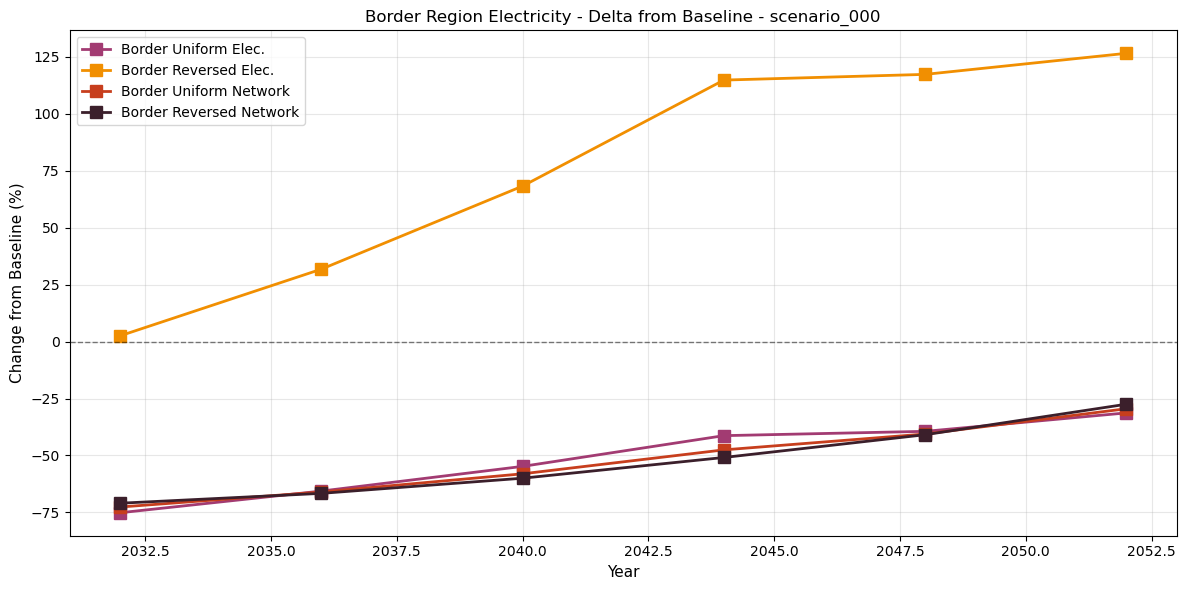

In [ ]:
# Delta from baseline over time
if 'baseline' in loaded_data:
    fig, ax = plt.subplots(figsize=(12, 6))
    
    baseline_by_year = df_multi[df_multi['Variant'] == 'baseline'].set_index('Year')['Total']
    
    for variant in VARIANTS:
        if variant in df_multi['Variant'].unique():
            variant_data = df_multi[df_multi['Variant'] == variant].set_index('Year')['Total']
            delta_pct = ((variant_data - baseline_by_year) / baseline_by_year * 100)
            
            ax.plot(delta_pct.index, delta_pct.values,
                   marker='s', linewidth=2, markersize=8,
                   label=VARIANT_LABELS.get(variant, variant),
                   color=VARIANT_COLORS.get(variant, 'gray'))
    
    ax.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.set_xlabel('Year', fontsize=11)
    ax.set_ylabel('Change from Baseline (%)', fontsize=11)
    ax.set_title(f'Border Region Electricity - Delta from Baseline - {BASE_SCENARIO}', fontsize=12)
    ax.legend(loc='best', fontsize=10)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(f'figures/border_sensitivity_{BASE_SCENARIO}_delta.pdf', bbox_inches='tight')
    plt.show()

## Compare Across Multiple Base Scenarios

In [ ]:
# Load multiple base scenarios for distribution analysis
SCENARIOS_TO_LOAD = [f'scenario_{i:03d}' for i in range(20)]  # First 20 scenarios
TARGET_YEAR_MULTI = 2040

all_scenario_results = []

for base_scenario in SCENARIOS_TO_LOAD:
    scenario_data = {}
    
    # Load baseline
    bl_results = baseline_results_dir / base_scenario
    bl_input = baseline_input_dir / base_scenario
    
    if bl_results.exists() and bl_input.exists():
        try:
            scenario_data['baseline'] = load_scenario(bl_results, bl_input)
        except:
            continue
    else:
        continue
    
    # Load variants
    for variant in VARIANTS:
        folder = f'{base_scenario}_{variant}'
        v_results = bs_results_dir / folder
        v_input = bs_input_dir / folder
        
        if v_results.exists() and v_input.exists():
            try:
                scenario_data[variant] = load_scenario(v_results, v_input)
            except:
                pass
    
    # Calculate electricity
    for variant, data in scenario_data.items():
        elec = calc_border_electricity(data, TARGET_YEAR_MULTI)
        all_scenario_results.append({
            'Base Scenario': base_scenario,
            'Variant': variant,
            'AT': elec['AT'],
            'IT': elec['IT'],
            'DE': elec['DE'],
            'Total': sum(elec.values())
        })
    
    print(f'Processed {base_scenario}: {len(scenario_data)} variants')

df_all = pd.DataFrame(all_scenario_results)
print(f'\nTotal records: {len(df_all)}')

Processed scenario_000: 5 variants
Processed scenario_001: 5 variants
Processed scenario_002: 5 variants
Processed scenario_003: 5 variants
Processed scenario_004: 5 variants
Processed scenario_005: 5 variants
Processed scenario_006: 5 variants
Processed scenario_007: 5 variants
Processed scenario_008: 5 variants
Processed scenario_009: 5 variants
Processed scenario_010: 5 variants
Processed scenario_011: 5 variants
Processed scenario_012: 5 variants
Processed scenario_013: 5 variants
Processed scenario_014: 5 variants
Processed scenario_015: 5 variants
Processed scenario_016: 5 variants
Processed scenario_017: 5 variants
Processed scenario_018: 5 variants
Processed scenario_019: 5 variants

Total records: 100


In [ ]:
# Summary statistics across all scenarios
summary = df_all.groupby('Variant').agg({
    'Total': ['mean', 'std', 'min', 'max', 'count']
}).round(2)

summary.columns = ['Mean (GWh)', 'Std', 'Min', 'Max', 'Count']
print(f'Summary Statistics Across All Scenarios - Year {TARGET_YEAR_MULTI}')
print('=' * 70)
display(summary)

Summary Statistics Across All Scenarios - Year 2040


,Mean (GWh),Std,Min,Max,Count
Variant,,,,,
baseline,2.11,1.70,0.21,4.60,20
border_rev_elec,2.06,2.74,0.00,7.68,20
border_rev_network,1.38,1.77,0.00,6.13,20
border_uni_elec,1.38,1.83,0.00,6.30,20
border_uni_network,1.29,1.72,0.00,6.00,20


C:\Users\simuser\AppData\Local\Temp\ipykernel_13732\3213457190.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(variant_data, patch_artist=True, labels=variant_labels_plot)


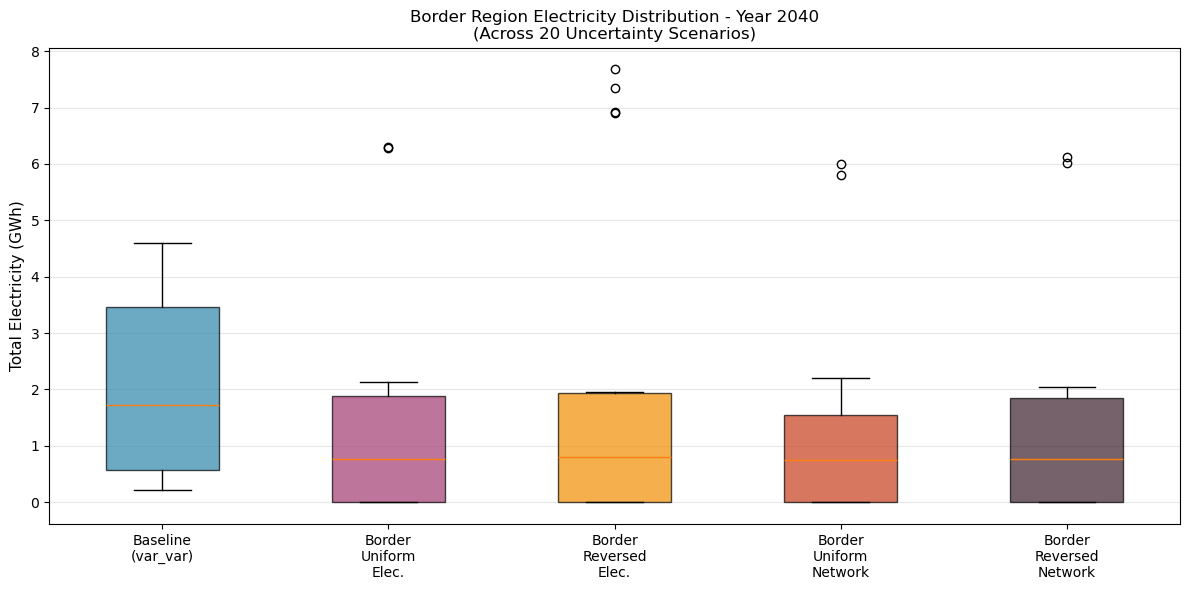

In [ ]:
# Box plot comparison across scenarios
fig, ax = plt.subplots(figsize=(12, 6))

variant_order = ['baseline'] + VARIANTS
variant_data = []
variant_labels_plot = []

for variant in variant_order:
    data = df_all[df_all['Variant'] == variant]['Total'].values
    if len(data) > 0:
        variant_data.append(data)
        variant_labels_plot.append(VARIANT_LABELS.get(variant, variant).replace(' ', '\n'))

bp = ax.boxplot(variant_data, patch_artist=True, labels=variant_labels_plot)

colors = [VARIANT_COLORS.get(v, 'gray') for v in variant_order if v in df_all['Variant'].unique()]
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_ylabel('Total Electricity (GWh)', fontsize=11)
ax.set_title(f'Border Region Electricity Distribution - Year {TARGET_YEAR_MULTI}\n(Across {len(SCENARIOS_TO_LOAD)} Uncertainty Scenarios)', fontsize=12)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(f'figures/border_sensitivity_distribution_{TARGET_YEAR_MULTI}.pdf', bbox_inches='tight')
plt.show()

In [ ]:
# Calculate delta from baseline for each scenario
if len(df_all) > 0:
    baseline_df = df_all[df_all['Variant'] == 'baseline'].set_index('Base Scenario')['Total']
    
    delta_results = []
    for variant in VARIANTS:
        variant_df = df_all[df_all['Variant'] == variant]
        for _, row in variant_df.iterrows():
            base_scenario = row['Base Scenario']
            if base_scenario in baseline_df.index:
                baseline_val = baseline_df[base_scenario]
                if baseline_val > 0:
                    delta_pct = ((row['Total'] - baseline_val) / baseline_val) * 100
                    delta_results.append({
                        'Base Scenario': base_scenario,
                        'Variant': variant,
                        'Delta (%)': delta_pct
                    })
    
    df_delta = pd.DataFrame(delta_results)
    
    # Summary of deltas
    delta_summary = df_delta.groupby('Variant')['Delta (%)'].agg(['mean', 'std', 'min', 'max']).round(2)
    print(f'Delta from Baseline (%) - Year {TARGET_YEAR_MULTI}')
    print('=' * 60)
    display(delta_summary)

Delta from Baseline (%) - Year 2040


,mean,std,min,max
Variant,,,,
border_rev_elec,-15.59,93.61,-100.0,156.00
border_rev_network,-38.31,69.98,-100.0,130.90
border_uni_elec,-40.60,65.67,-100.0,114.54
border_uni_network,-45.34,60.21,-100.0,116.42


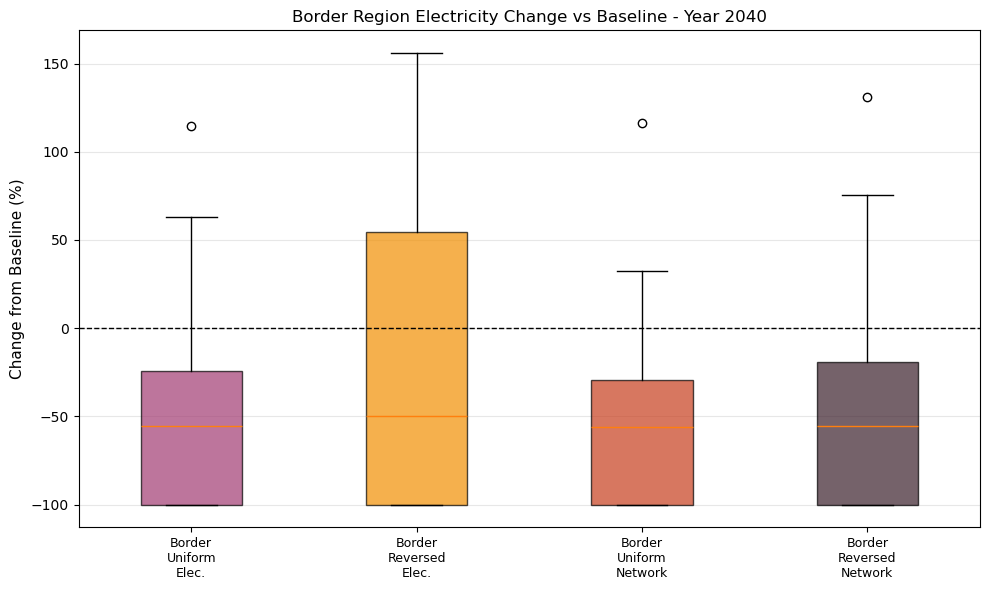

In [ ]:
# Delta distribution plot
if len(df_delta) > 0:
    fig, ax = plt.subplots(figsize=(10, 6))
    
    positions = range(len(VARIANTS))
    delta_data = [df_delta[df_delta['Variant'] == v]['Delta (%)'].values for v in VARIANTS]
    
    bp = ax.boxplot(delta_data, patch_artist=True, positions=positions)
    
    for i, (patch, variant) in enumerate(zip(bp['boxes'], VARIANTS)):
        patch.set_facecolor(VARIANT_COLORS.get(variant, 'gray'))
        patch.set_alpha(0.7)
    
    ax.axhline(y=0, color='black', linestyle='--', linewidth=1)
    ax.set_xticks(positions)
    ax.set_xticklabels([VARIANT_LABELS[v].replace(' ', '\n') for v in VARIANTS], fontsize=9)
    ax.set_ylabel('Change from Baseline (%)', fontsize=11)
    ax.set_title(f'Border Region Electricity Change vs Baseline - Year {TARGET_YEAR_MULTI}', fontsize=12)
    ax.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.savefig(f'figures/border_sensitivity_delta_distribution_{TARGET_YEAR_MULTI}.pdf', bbox_inches='tight')
    plt.show()

## Save Results

In [ ]:
# Save all results to CSV
if len(df_all) > 0:
    df_all.to_csv(f'border_sensitivity_results_{TARGET_YEAR_MULTI}.csv', index=False)
    print(f'Saved: border_sensitivity_results_{TARGET_YEAR_MULTI}.csv')

if len(df_delta) > 0:
    df_delta.to_csv(f'border_sensitivity_delta_{TARGET_YEAR_MULTI}.csv', index=False)
    print(f'Saved: border_sensitivity_delta_{TARGET_YEAR_MULTI}.csv')

Saved: border_sensitivity_results_2040.csv
Saved: border_sensitivity_delta_2040.csv


In [ ]:
# OPTIMIZED loading functions - use CSafeLoader and skip unnecessary files

def load_scenario_fast(results_path, input_path):
    """
    Fast loading - only loads what's needed for analysis.
    Uses CSafeLoader for 10x speedup.
    """
    data = {'input_data': {}, 'output_data': {}}
    
    # Use CSafeLoader if available (much faster)
    try:
        Loader = yaml.CSafeLoader
    except AttributeError:
        Loader = yaml.SafeLoader
    
    # Load only essential input files (small files)
    essential_inputs = ['GeographicElement.yaml', 'Fuel.yaml', 'TechVehicle.yaml', 'Technology.yaml']
    for fname in essential_inputs:
        fpath = Path(input_path) / fname
        if fpath.exists():
            with open(fpath, 'r', encoding='utf-8') as f:
                data['input_data'][fname.replace('.yaml', '')] = yaml.load(f, Loader=Loader)
    
    # Load s_dict (energy supply) - LARGE FILE, needed for electricity
    results_path = Path(results_path)
    for fname in os.listdir(results_path):
        if fname.endswith('_s_dict.yaml'):
            with open(results_path / fname, 'r', encoding='utf-8') as f:
                data['output_data']['s'] = yaml.load(f, Loader=Loader)
            break
    
    # Load h_dict (vehicle fleet) - needed for BEV count
    for fname in os.listdir(results_path):
        if fname.endswith('_h_dict.yaml'):
            with open(results_path / fname, 'r', encoding='utf-8') as f:
                data['output_data']['h'] = yaml.load(f, Loader=Loader)
            break
    
    return data


def calc_bev_fleet(data, target_year):
    """
    Calculate total BEV fleet size for a given year.
    Returns BEV count and total fleet count.
    
    h_dict key structure: (year, odpair_id, tech_vehicle_id, purchase_year)
    TechVehicle has 'technology' field which is an ID
    Technology has 'id' and 'name' - BEV has name='BEV'
    """
    h_data = data['output_data'].get('h', {})
    input_data = data['input_data']
    
    if not h_data:
        return {'bev': 0, 'total': 0, 'bev_share': 0}
    
    # Get BEV technology ID from Technology.yaml
    technologies = input_data.get('Technology', [])
    bev_tech_id = None
    for tech in technologies:
        if tech.get('name', '').upper() == 'BEV':
            bev_tech_id = tech.get('id')
            break
    
    # Map TechVehicle ID to Technology ID
    tech_vehicles = input_data.get('TechVehicle', [])
    bev_tv_ids = set()
    for tv in tech_vehicles:
        tv_id = tv.get('id')
        tech_id = tv.get('technology')
        if tech_id == bev_tech_id:
            bev_tv_ids.add(tv_id)
    
    bev_count = 0
    total_count = 0
    
    for key_str, count in h_data.items():
        try:
            # h_dict key: (year, odpair_id, tech_vehicle_id, purchase_year)
            key = eval(key_str) if isinstance(key_str, str) else key_str
            year = key[0]
            tv_id = key[2]  # tech_vehicle_id is at index 2
            count = float(count)
            
            if year != target_year or count <= 0:
                continue
            
            total_count += count
            if tv_id in bev_tv_ids:
                bev_count += count
        except:
            continue
    
    bev_share = (bev_count / total_count * 100) if total_count > 0 else 0
    
    return {
        'bev': bev_count,
        'total': total_count,
        'bev_share': bev_share
    }


print('Optimized loading functions defined')
print('  - Uses CSafeLoader (10x faster than SafeLoader)')
print('  - Fixed BEV detection: looks up Technology.yaml for BEV ID')
print('  - h_dict key: (year, odpair_id, tech_vehicle_id, purchase_year)')

Optimized loading functions defined
  - Uses CSafeLoader (10x faster than SafeLoader)
  - Fixed BEV detection: looks up Technology.yaml for BEV ID
  - h_dict key: (year, odpair_id, tech_vehicle_id, purchase_year)


In [ ]:
# Load ALL scenarios - WITH CACHING
# If cached results exist, load from CSV (instant)
# Otherwise, process all scenarios and save cache

import time

ALL_SCENARIOS = [f'scenario_{i:03d}' for i in range(24)]
ANALYSIS_YEARS = [2032, 2036, 2040, 2044, 2048, 2052]
CACHE_FILE = 'border_sensitivity_cache.csv'

# Check for cached results first
if Path(CACHE_FILE).exists():
    print(f'Loading from cache: {CACHE_FILE}')
    df_full = pd.read_csv(CACHE_FILE)
    print(f'Loaded {len(df_full)} records from cache')
    print(f'Scenarios: {df_full["Base Scenario"].nunique()}')
    print(f'Variants: {df_full["Variant"].unique().tolist()}')
    
    # Check if BEV data looks valid (not all zeros)
    if df_full['BEV_count'].sum() == 0 and df_full['Total_fleet'].sum() > 0:
        print('\nWARNING: BEV_count is all zeros but Total_fleet has data.')
        print('Cache may have been generated with incorrect BEV detection.')
        print('Delete border_sensitivity_cache.csv and re-run to regenerate.')
else:
    print('No cache found. Loading all scenarios...')
    print('=' * 60)
    print('Using CSafeLoader for faster YAML parsing')
    print('')
    
    # Use CSafeLoader if available
    try:
        Loader = yaml.CSafeLoader
        print('CSafeLoader available - 10x faster')
    except AttributeError:
        Loader = yaml.SafeLoader
        print('Using SafeLoader (slower)')
    
    start_time = time.time()
    full_results = []
    loaded_count = 0
    
    for base_scenario in ALL_SCENARIOS:
        scenario_start = time.time()
        variants_loaded = []
        
        # Build list of (variant, results_path, input_path)
        tasks = []
        
        # Baseline
        bl_results = baseline_results_dir / base_scenario
        bl_input = baseline_input_dir / base_scenario
        if not bl_input.exists():
            bl_input = bs_input_dir / f'{base_scenario}_border_uni_elec'
        
        if bl_results.exists() and bl_input.exists():
            tasks.append(('baseline', bl_results, bl_input))
        
        # Variants
        for variant in VARIANTS:
            folder = f'{base_scenario}_{variant}'
            v_results = bs_results_dir / folder
            v_input = bs_input_dir / folder
            if v_results.exists() and v_input.exists():
                tasks.append((variant, v_results, v_input))
        
        # Process each variant
        for variant, results_path, input_path in tasks:
            try:
                # Load input data - INCLUDE Technology.yaml for BEV detection!
                input_data = {}
                for fname in ['GeographicElement.yaml', 'Fuel.yaml', 'TechVehicle.yaml', 'Technology.yaml']:
                    fpath = input_path / fname
                    if fpath.exists():
                        with open(fpath, 'r', encoding='utf-8') as f:
                            input_data[fname.replace('.yaml', '')] = yaml.load(f, Loader=Loader)
                
                # Load s_dict
                s_data = {}
                for fname in os.listdir(results_path):
                    if fname.endswith('_s_dict.yaml'):
                        with open(results_path / fname, 'r', encoding='utf-8') as f:
                            s_data = yaml.load(f, Loader=Loader)
                        break
                
                # Load h_dict
                h_data = {}
                for fname in os.listdir(results_path):
                    if fname.endswith('_h_dict.yaml'):
                        with open(results_path / fname, 'r', encoding='utf-8') as f:
                            h_data = yaml.load(f, Loader=Loader)
                        break
                
                # Calculate metrics for all years
                data = {'input_data': input_data, 'output_data': {'s': s_data, 'h': h_data}}
                
                for year in ANALYSIS_YEARS:
                    elec = calc_border_electricity(data, year)
                    bev = calc_bev_fleet(data, year)
                    
                    full_results.append({
                        'Base Scenario': base_scenario,
                        'Variant': variant,
                        'Year': year,
                        'AT_elec': elec['AT'],
                        'IT_elec': elec['IT'],
                        'DE_elec': elec['DE'],
                        'Total_elec': sum(elec.values()),
                        'BEV_count': bev['bev'],
                        'Total_fleet': bev['total'],
                        'BEV_share': bev['bev_share']
                    })
                
                variants_loaded.append(variant)
                
            except Exception as e:
                print(f'  Error loading {base_scenario}_{variant}: {e}')
        
        loaded_count += 1
        elapsed = time.time() - scenario_start
        print(f'[{loaded_count:2d}/24] {base_scenario}: {len(variants_loaded)} variants ({elapsed:.1f}s)')
    
    total_time = time.time() - start_time
    df_full = pd.DataFrame(full_results)
    
    # Save cache
    if len(df_full) > 0:
        df_full.to_csv(CACHE_FILE, index=False)
        print(f'\nCache saved to: {CACHE_FILE}')
    
    print(f'\nTotal time: {total_time/60:.1f} minutes')
    print(f'Total records: {len(df_full)}')
    
    # Print BEV summary to verify detection is working
    if len(df_full) > 0:
        print(f'\nBEV Detection Check:')
        print(f'  Total fleet sum: {df_full["Total_fleet"].sum():.0f}')
        print(f'  BEV count sum: {df_full["BEV_count"].sum():.0f}')
        print(f'  Mean BEV share: {df_full["BEV_share"].mean():.1f}%')

Loading from cache: border_sensitivity_cache.csv
Loaded 720 records from cache
Scenarios: 24
Variants: ['baseline', 'border_uni_elec', 'border_rev_elec', 'border_uni_network', 'border_rev_network']


### Border Electricity Summary - All Scenarios

In [ ]:
# Summary statistics for border electricity across all scenarios
if len(df_full) > 0:
    # Group by variant and year
    elec_summary = df_full.groupby(['Variant', 'Year'])['Total_elec'].agg(['mean', 'std', 'min', 'max', 'count']).round(3)
    elec_summary.columns = ['Mean (GWh)', 'Std', 'Min', 'Max', 'N']
    
    print('Border Electricity Summary - All 24 Scenarios')
    print('=' * 80)
    display(elec_summary)
else:
    print('No data loaded')

Border Electricity Summary - All 24 Scenarios


Mean (GWh)    Std    Min    Max   N
Variant            Year                                     
baseline           2032       1.069  0.672  0.397  2.675  24
                   2036       1.462  1.051  0.426  3.693  24
                   2040       1.915  1.675  0.213  4.600  24
                   2044       2.889  1.896  0.324  5.819  24
                   2048       3.369  1.786  0.513  6.082  24
                   2052       3.504  1.740  0.400  6.271  24
border_rev_elec    2032       0.882  0.926  0.090  3.152  24
                   2036       1.254  1.395  0.100  4.709  24
                   2040       1.630  2.048  0.092  6.259  24
                   2044       2.349  2.465  0.096  7.591  24
                   2048       2.687  2.452  0.123  7.742  24
                   2052       2.840  2.392  0.107  7.685  24
border_rev_network 2032       0.704  0.651  0.089  2.260  24
                   2036       0.878  0.819  0.106  2.522  24
                   2040       1.087  1.153  0.094  3.955  24
                   2044       1.365  1.349  0.097  4.966  24
                   2048       1.571  1.374  0.135  5.197  24
                   2052       1.648  1.369  0.110  5.333  24
border_uni_elec    2032       0.924  0.825  0.087  2.971  24
                   2036       1.260  1.338  0.098  4.401  24
                   2040       1.722  1.973  0.096  5.761  24
                   2044       2.295  2.468  0.073  6.896  24
                   2048       2.528  2.481  0.123  7.047  24
                   2052       2.575  2.434  0.093  6.971  24
border_uni_network 2032       0.693  0.647  0.089  2.256  24
                   2036       0.869  0.813  0.108  2.515  24
                   2040       1.038  1.135  0.104  3.928  24
                   2044       1.301  1.325  0.110  4.918  24
                   2048       1.484  1.352  0.130  5.150  24
                   2052       1.548  1.365  0.111  5.296  24

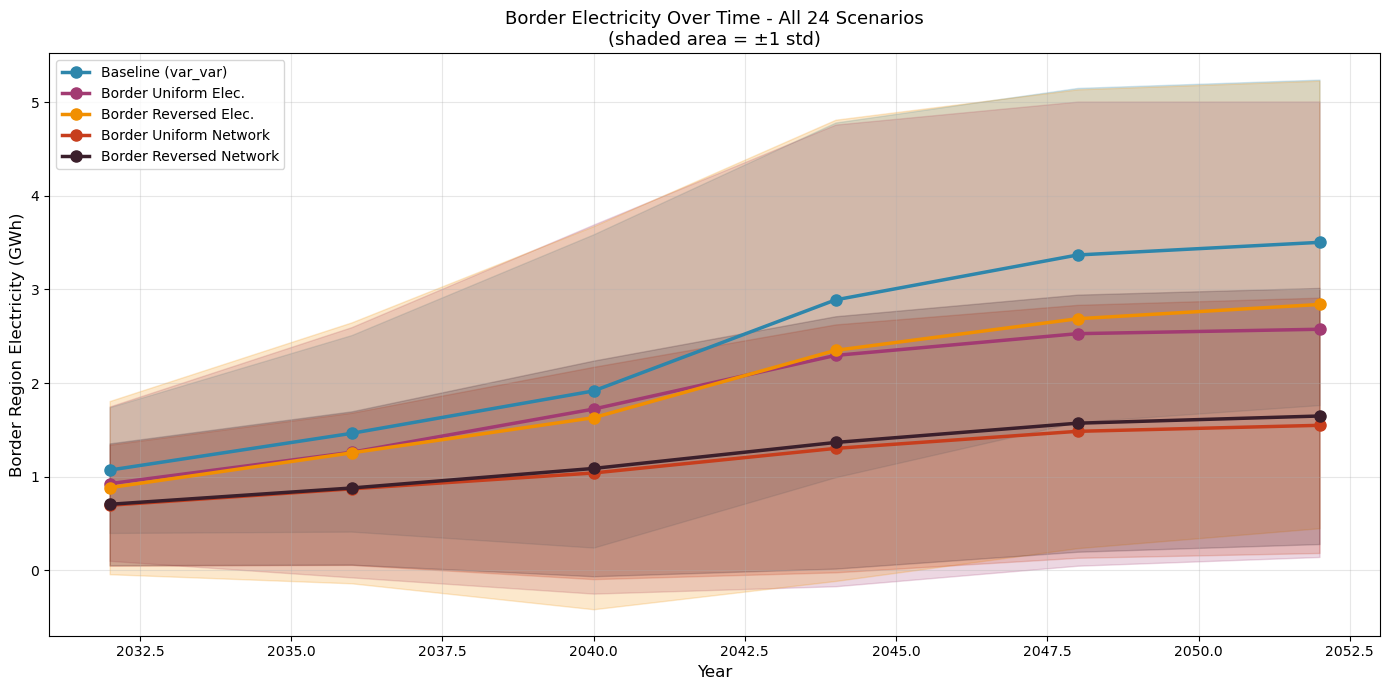

Saved: figures/border_sensitivity_all_scenarios_timeseries.pdf


In [ ]:
# Electricity time series with uncertainty bands - all scenarios
if len(df_full) > 0:
    fig, ax = plt.subplots(figsize=(14, 7))
    
    for variant in ['baseline'] + VARIANTS:
        variant_data = df_full[df_full['Variant'] == variant]
        if len(variant_data) == 0:
            continue
        
        # Group by year
        grouped = variant_data.groupby('Year')['Total_elec'].agg(['mean', 'std', 'min', 'max'])
        years = grouped.index.values
        means = grouped['mean'].values
        stds = grouped['std'].fillna(0).values
        
        color = VARIANT_COLORS.get(variant, 'gray')
        label = VARIANT_LABELS.get(variant, variant)
        
        # Plot mean line
        ax.plot(years, means, marker='o', linewidth=2.5, markersize=8, 
               color=color, label=label)
        
        # Plot uncertainty band (mean ± std)
        if stds.sum() > 0:
            ax.fill_between(years, means - stds, means + stds, 
                           alpha=0.2, color=color)
    
    ax.set_xlabel('Year', fontsize=12)
    ax.set_ylabel('Border Region Electricity (GWh)', fontsize=12)
    ax.set_title('Border Electricity Over Time - All 24 Scenarios\n(shaded area = ±1 std)', fontsize=13)
    ax.legend(loc='upper left', fontsize=10)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('figures/border_sensitivity_all_scenarios_timeseries.pdf', bbox_inches='tight')
    plt.show()
    print('Saved: figures/border_sensitivity_all_scenarios_timeseries.pdf')

### BEV Fleet Electrification Comparison

In [ ]:
# BEV Fleet Summary - All Scenarios
if len(df_full) > 0:
    # Group by variant and year
    bev_summary = df_full.groupby(['Variant', 'Year']).agg({
        'BEV_count': ['mean', 'std', 'min', 'max'],
        'BEV_share': ['mean', 'std', 'min', 'max']
    }).round(2)
    
    print('BEV Fleet Summary - All 24 Scenarios')
    print('=' * 80)
    display(bev_summary)

BEV Fleet Summary - All 24 Scenarios


BEV_count                             BEV_share  \
                             mean      std      min       max      mean   
Variant            Year                                                   
baseline           2032   2559.25  1454.24  1000.23   5387.69     10.34   
                   2036   3683.22  2533.76  1147.75   8718.49     13.84   
                   2040   5312.17  4274.73  1000.00  12660.94     17.96   
                   2044   8330.95  5249.30  1304.08  16943.80     28.50   
                   2048  10829.87  5403.96  1936.58  18640.70     35.81   
                   2052  12484.14  5969.70  1607.42  19962.69     40.64   
border_rev_elec    2032   2559.27  1454.23  1000.25   5387.65     10.34   
                   2036   3683.28  2533.74  1147.59   8718.41     13.84   
                   2040   5312.24  4274.72  1000.00  12660.85     17.96   
                   2044   8331.04  5249.28  1304.11  16943.70     28.50   
                   2048  10829.98  5403.94  1936.81  18640.06     35.81   
                   2052  12484.50  5969.51  1607.49  19962.20     40.64   
border_rev_network 2032   2559.85  1454.52  1000.15   5387.78     10.34   
                   2036   3684.62  2533.29  1150.46   8716.25     13.84   
                   2040   5310.53  4276.17  1000.00  12658.47     17.95   
                   2044   8330.08  5249.65  1306.08  16941.02     28.50   
                   2048  10829.89  5409.59  1940.78  18644.06     35.81   
                   2052  12485.07  5971.84  1630.52  19963.89     40.64   
border_uni_elec    2032   2559.17  1454.26  1000.23   5387.41     10.34   
                   2036   3683.19  2533.74  1147.54   8718.00     13.84   
                   2040   5312.17  4274.69  1000.00  12660.40     17.96   
                   2044   8330.96  5249.24  1304.09  16943.19     28.50   
                   2048  10829.75  5403.84  1936.46  18638.11     35.81   
                   2052  12484.11  5969.69  1607.15  19960.24     40.64   
border_uni_network 2032   2561.20  1452.76  1000.74   5387.79     10.35   
                   2036   3685.53  2531.89  1151.07   8716.83     13.85   
                   2040   5312.44  4274.45  1000.00  12659.11     17.96   
                   2044   8331.86  5248.17  1309.19  16941.74     28.51   
                   2048  10832.90  5402.45  1958.63  18641.70     35.82   
                   2052  12490.34  5963.52  1649.17  19963.64     40.66   

                                             
                           std   min    max  
Variant            Year                      
baseline           2032   5.71  4.16  21.17  
                   2036   9.13  4.52  31.23  
                   2040  13.71  3.78  41.23  
                   2044  17.36  4.69  56.17  
                   2048  17.42  6.65  60.39  
                   2052  19.31  5.31  64.75  
border_rev_elec    2032   5.71  4.16  21.17  
                   2036   9.13  4.52  31.23  
                   2040  13.71  3.78  41.23  
                   2044  17.36  4.69  56.17  
                   2048  17.42  6.65  60.38  
                   2052  19.31  5.31  64.75  
border_rev_network 2032   5.71  4.16  21.17  
                   2036   9.13  4.53  31.24  
                   2040  13.72  3.78  41.22  
                   2044  17.36  4.70  56.16  
                   2048  17.44  6.67  60.40  
                   2052  19.31  5.39  64.75  
border_uni_elec    2032   5.71  4.16  21.17  
                   2036   9.13  4.52  31.23  
                   2040  13.71  3.78  41.23  
                   2044  17.36  4.69  56.16  
                   2048  17.42  6.65  60.38  
                   2052  19.31  5.31  64.74  
border_uni_network 2032   5.70  4.16  21.17  
                   2036   9.12  4.54  31.24  
                   2040  13.71  3.78  41.23  
                   2044  17.35  4.71  56.16  
                   2048  17.42  6.73  60.39  
                   2052  19.29  5.45  64.75

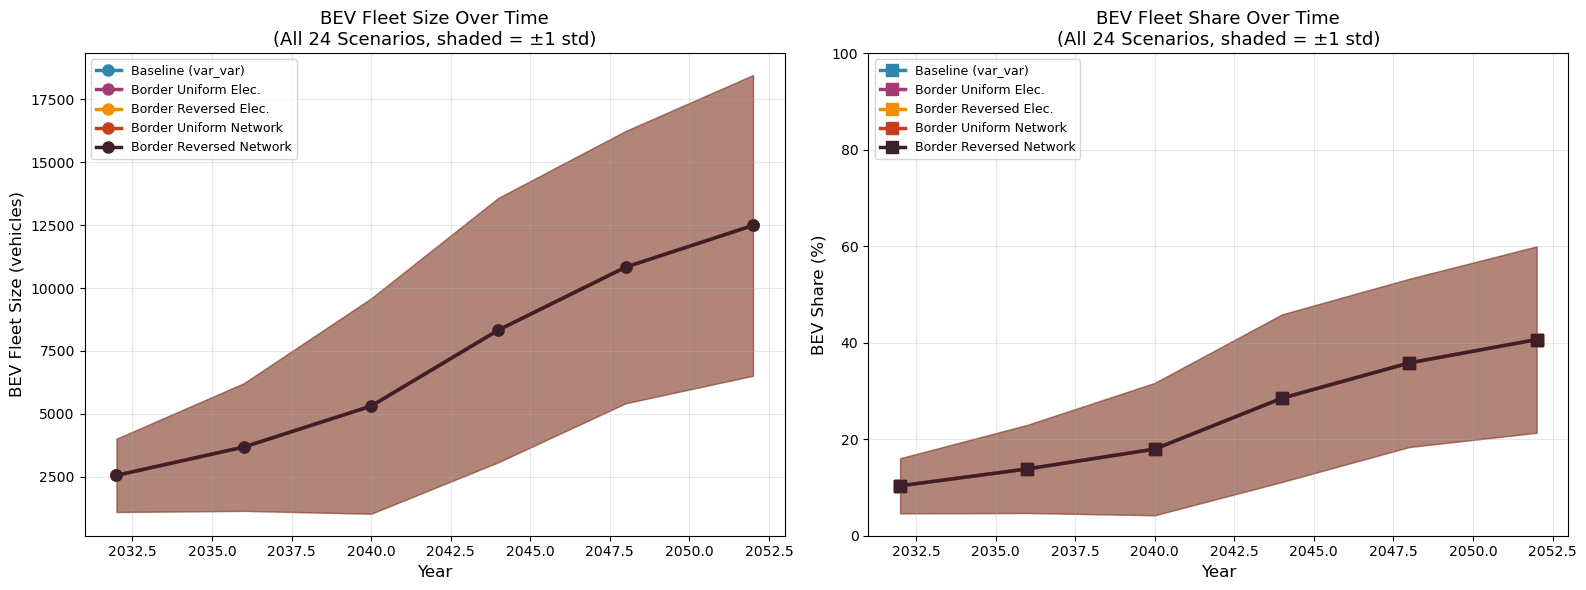

Saved: figures/border_sensitivity_bev_fleet_timeseries.pdf


In [ ]:
# BEV Fleet Size Over Time - All Scenarios
if len(df_full) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Plot 1: Absolute BEV count
    ax1 = axes[0]
    for variant in ['baseline'] + VARIANTS:
        variant_data = df_full[df_full['Variant'] == variant]
        if len(variant_data) == 0:
            continue
        
        grouped = variant_data.groupby('Year')['BEV_count'].agg(['mean', 'std'])
        years = grouped.index.values
        means = grouped['mean'].values
        stds = grouped['std'].fillna(0).values
        
        color = VARIANT_COLORS.get(variant, 'gray')
        label = VARIANT_LABELS.get(variant, variant)
        
        ax1.plot(years, means, marker='o', linewidth=2.5, markersize=8, 
                color=color, label=label)
        if stds.sum() > 0:
            ax1.fill_between(years, means - stds, means + stds, alpha=0.2, color=color)
    
    ax1.set_xlabel('Year', fontsize=12)
    ax1.set_ylabel('BEV Fleet Size (vehicles)', fontsize=12)
    ax1.set_title('BEV Fleet Size Over Time\n(All 24 Scenarios, shaded = ±1 std)', fontsize=13)
    ax1.legend(loc='upper left', fontsize=9)
    ax1.grid(True, alpha=0.3)
    
    # Plot 2: BEV Share (%)
    ax2 = axes[1]
    for variant in ['baseline'] + VARIANTS:
        variant_data = df_full[df_full['Variant'] == variant]
        if len(variant_data) == 0:
            continue
        
        grouped = variant_data.groupby('Year')['BEV_share'].agg(['mean', 'std'])
        years = grouped.index.values
        means = grouped['mean'].values
        stds = grouped['std'].fillna(0).values
        
        color = VARIANT_COLORS.get(variant, 'gray')
        label = VARIANT_LABELS.get(variant, variant)
        
        ax2.plot(years, means, marker='s', linewidth=2.5, markersize=8, 
                color=color, label=label)
        if stds.sum() > 0:
            ax2.fill_between(years, means - stds, means + stds, alpha=0.2, color=color)
    
    ax2.set_xlabel('Year', fontsize=12)
    ax2.set_ylabel('BEV Share (%)', fontsize=12)
    ax2.set_title('BEV Fleet Share Over Time\n(All 24 Scenarios, shaded = ±1 std)', fontsize=13)
    ax2.legend(loc='upper left', fontsize=9)
    ax2.grid(True, alpha=0.3)
    ax2.set_ylim(0, 100)
    
    plt.tight_layout()
    plt.savefig('figures/border_sensitivity_bev_fleet_timeseries.pdf', bbox_inches='tight')
    plt.show()
    print('Saved: figures/border_sensitivity_bev_fleet_timeseries.pdf')

In [ ]:
# Calculate BEV delta from baseline for each scenario
df_bev_delta = pd.DataFrame()  # Initialize empty dataframe

if 'df_full' in dir() and len(df_full) > 0:
    baseline_bev = df_full[df_full['Variant'] == 'baseline'].set_index(['Base Scenario', 'Year'])['BEV_count']
    
    bev_delta_results = []
    for variant in VARIANTS:
        variant_df = df_full[df_full['Variant'] == variant]
        for _, row in variant_df.iterrows():
            key = (row['Base Scenario'], row['Year'])
            if key in baseline_bev.index:
                baseline_val = baseline_bev[key]
                if baseline_val > 0:
                    delta_pct = ((row['BEV_count'] - baseline_val) / baseline_val) * 100
                    delta_abs = row['BEV_count'] - baseline_val
                    bev_delta_results.append({
                        'Base Scenario': row['Base Scenario'],
                        'Year': row['Year'],
                        'Variant': variant,
                        'BEV_delta_pct': delta_pct,
                        'BEV_delta_abs': delta_abs
                    })
    
    df_bev_delta = pd.DataFrame(bev_delta_results)
    
    if len(df_bev_delta) > 0:
        # Summary by variant and year
        bev_delta_summary = df_bev_delta.groupby(['Variant', 'Year'])['BEV_delta_pct'].agg(['mean', 'std', 'min', 'max']).round(2)
        print('BEV Fleet Change vs Baseline (%) - All Scenarios')
        print('=' * 80)
        display(bev_delta_summary)
    else:
        print('No BEV delta data calculated. Check if baseline scenarios were loaded.')
else:
    print('df_full not available. Run the scenario loading cell first.')

BEV Fleet Change vs Baseline (%) - All Scenarios


mean   std   min   max
Variant            Year                        
border_rev_elec    2032  0.00  0.02 -0.03  0.06
                   2036  0.00  0.02 -0.03  0.05
                   2040  0.00  0.01 -0.04  0.04
                   2044  0.00  0.00 -0.01  0.01
                   2048  0.00  0.00 -0.00  0.01
                   2052  0.01  0.02 -0.02  0.12
border_rev_network 2032 -0.01  0.69 -1.51  1.77
                   2036  0.04  0.59 -1.31  1.50
                   2040 -0.12  0.40 -1.43  0.21
                   2044 -0.01  0.16 -0.43  0.24
                   2048 -0.02  0.15 -0.25  0.23
                   2052  0.08  0.44 -0.35  1.44
border_uni_elec    2032 -0.00  0.01 -0.04  0.02
                   2036 -0.00  0.01 -0.02  0.02
                   2040  0.00  0.01 -0.02  0.02
                   2044  0.00  0.00 -0.01  0.02
                   2048 -0.00  0.01 -0.01  0.01
                   2052 -0.00  0.01 -0.02  0.01
border_uni_network 2032  0.14  0.29 -0.00  0.97
                   2036  0.14  0.24 -0.02  0.80
                   2040  0.02  0.06 -0.06  0.18
                   2044  0.05  0.12 -0.04  0.40
                   2048  0.10  0.33 -0.16  1.14
                   2052  0.26  0.74 -0.17  2.61

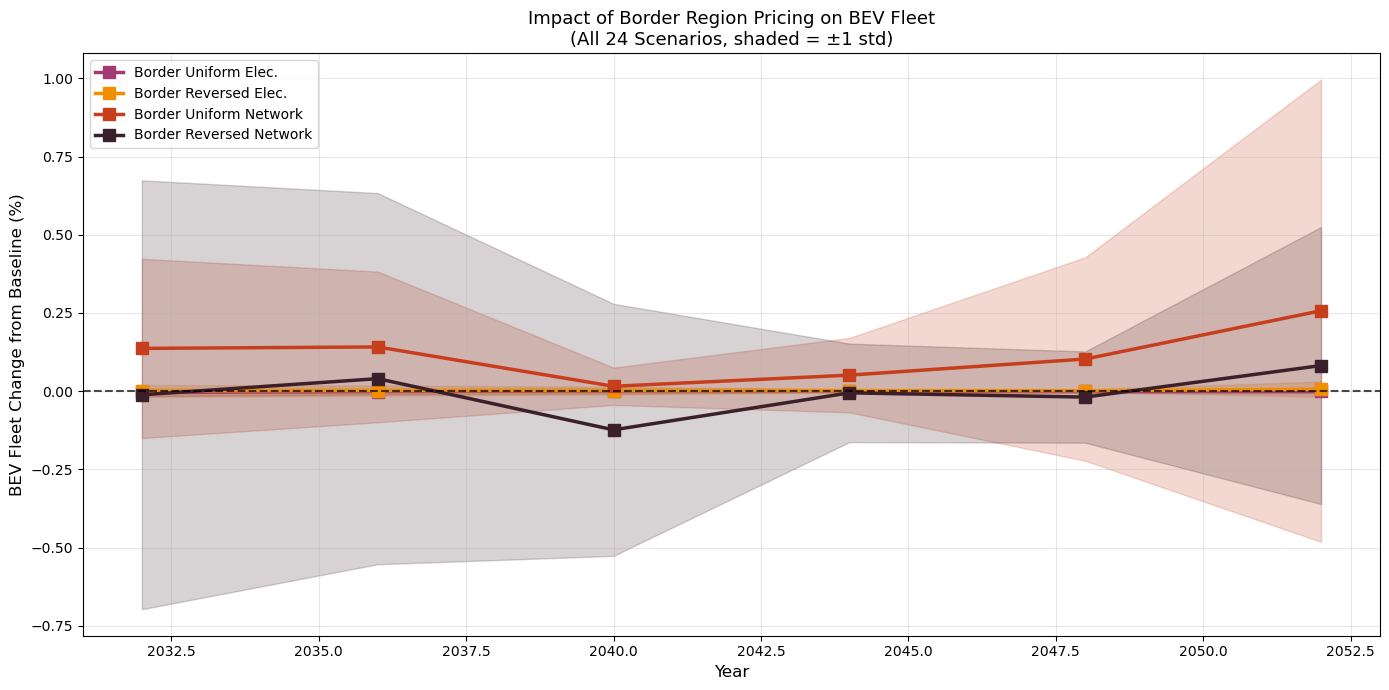

Saved: figures/border_sensitivity_bev_delta_timeseries.pdf


In [ ]:
# BEV Delta visualization over time
if 'df_bev_delta' in dir() and len(df_bev_delta) > 0:
    fig, ax = plt.subplots(figsize=(14, 7))
    
    for variant in VARIANTS:
        variant_data = df_bev_delta[df_bev_delta['Variant'] == variant]
        if len(variant_data) == 0:
            continue
        
        grouped = variant_data.groupby('Year')['BEV_delta_pct'].agg(['mean', 'std'])
        years = grouped.index.values
        means = grouped['mean'].values
        stds = grouped['std'].fillna(0).values
        
        color = VARIANT_COLORS.get(variant, 'gray')
        label = VARIANT_LABELS.get(variant, variant)
        
        ax.plot(years, means, marker='s', linewidth=2.5, markersize=8, 
               color=color, label=label)
        if stds.sum() > 0:
            ax.fill_between(years, means - stds, means + stds, alpha=0.2, color=color)
    
    ax.axhline(y=0, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
    ax.set_xlabel('Year', fontsize=12)
    ax.set_ylabel('BEV Fleet Change from Baseline (%)', fontsize=12)
    ax.set_title('Impact of Border Region Pricing on BEV Fleet\n(All 24 Scenarios, shaded = ±1 std)', fontsize=13)
    ax.legend(loc='best', fontsize=10)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('figures/border_sensitivity_bev_delta_timeseries.pdf', bbox_inches='tight')
    plt.show()
    print('Saved: figures/border_sensitivity_bev_delta_timeseries.pdf')
else:
    print('No BEV delta data available. Run the previous cells first to load all scenarios.')

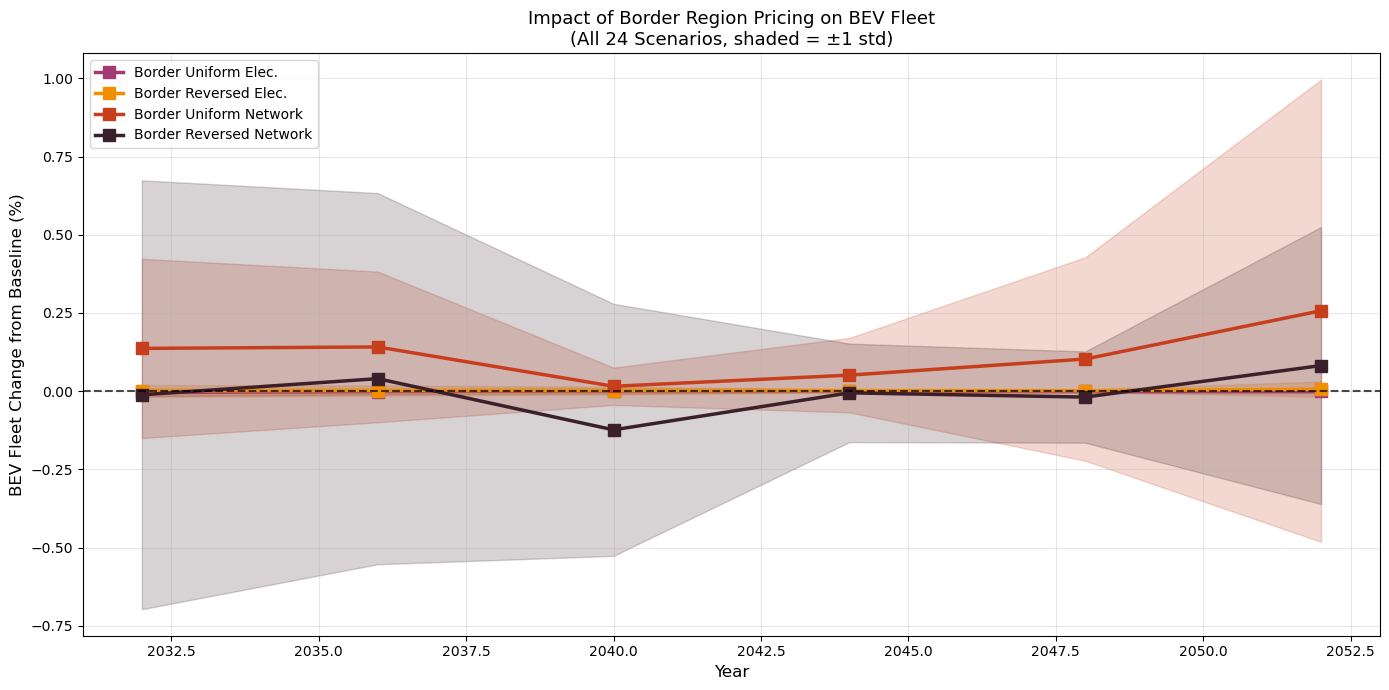

Saved: figures/border_sensitivity_bev_delta_timeseries.pdf


In [ ]:
# BEV Delta visualization over time
if len(df_bev_delta) > 0:
    fig, ax = plt.subplots(figsize=(14, 7))
    
    for variant in VARIANTS:
        variant_data = df_bev_delta[df_bev_delta['Variant'] == variant]
        if len(variant_data) == 0:
            continue
        
        grouped = variant_data.groupby('Year')['BEV_delta_pct'].agg(['mean', 'std'])
        years = grouped.index.values
        means = grouped['mean'].values
        stds = grouped['std'].fillna(0).values
        
        color = VARIANT_COLORS.get(variant, 'gray')
        label = VARIANT_LABELS.get(variant, variant)
        
        ax.plot(years, means, marker='s', linewidth=2.5, markersize=8, 
               color=color, label=label)
        if stds.sum() > 0:
            ax.fill_between(years, means - stds, means + stds, alpha=0.2, color=color)
    
    ax.axhline(y=0, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
    ax.set_xlabel('Year', fontsize=12)
    ax.set_ylabel('BEV Fleet Change from Baseline (%)', fontsize=12)
    ax.set_title('Impact of Border Region Pricing on BEV Fleet\n(All 24 Scenarios, shaded = ±1 std)', fontsize=13)
    ax.legend(loc='best', fontsize=10)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('figures/border_sensitivity_bev_delta_timeseries.pdf', bbox_inches='tight')
    plt.show()
    print('Saved: figures/border_sensitivity_bev_delta_timeseries.pdf')

### Combined Summary: Electricity vs Electrification

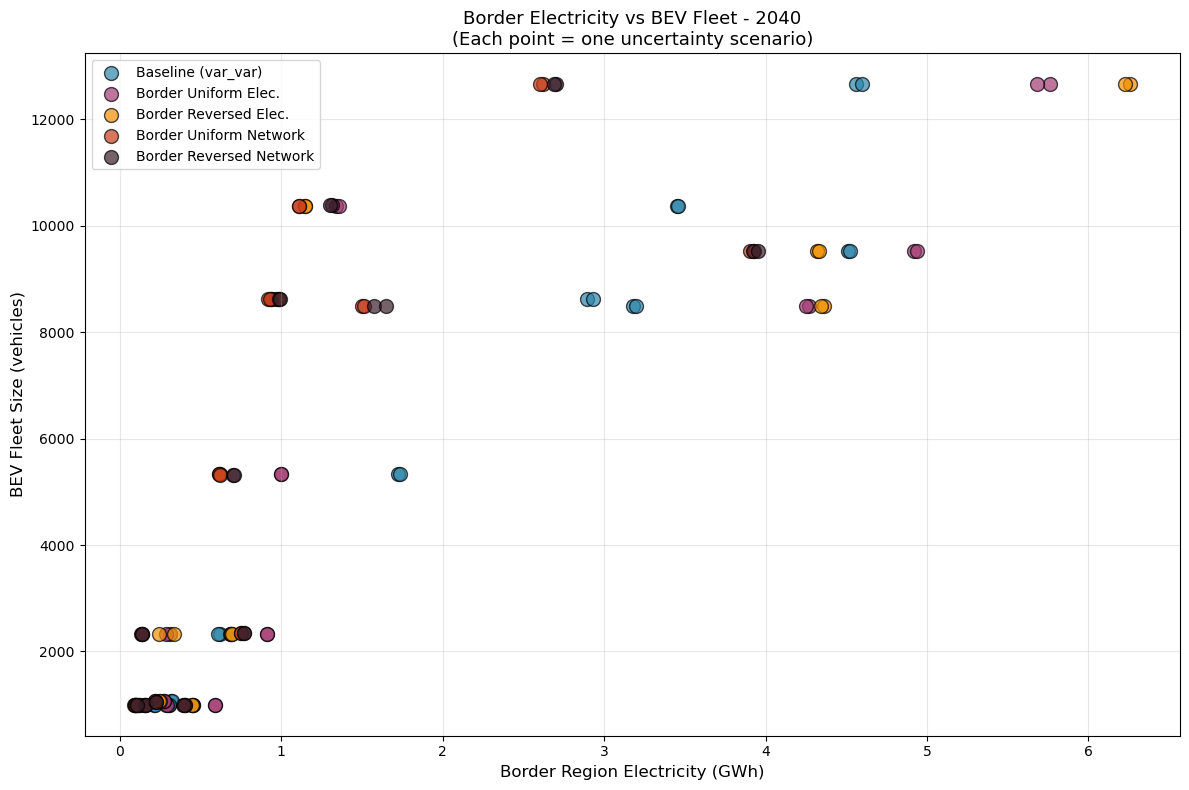

Saved: figures/border_sensitivity_elec_vs_bev_2040.pdf


In [ ]:
# Combined scatter plot: Electricity vs BEV at 2040
if len(df_full) > 0:
    TARGET = 2040
    year_data = df_full[df_full['Year'] == TARGET]
    
    fig, ax = plt.subplots(figsize=(12, 8))
    
    for variant in ['baseline'] + VARIANTS:
        v_data = year_data[year_data['Variant'] == variant]
        if len(v_data) == 0:
            continue
        
        color = VARIANT_COLORS.get(variant, 'gray')
        label = VARIANT_LABELS.get(variant, variant)
        
        ax.scatter(v_data['Total_elec'], v_data['BEV_count'], 
                  s=100, alpha=0.7, color=color, label=label, edgecolor='black')
    
    ax.set_xlabel('Border Region Electricity (GWh)', fontsize=12)
    ax.set_ylabel('BEV Fleet Size (vehicles)', fontsize=12)
    ax.set_title(f'Border Electricity vs BEV Fleet - {TARGET}\n(Each point = one uncertainty scenario)', fontsize=13)
    ax.legend(loc='best', fontsize=10)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(f'figures/border_sensitivity_elec_vs_bev_{TARGET}.pdf', bbox_inches='tight')
    plt.show()
    print(f'Saved: figures/border_sensitivity_elec_vs_bev_{TARGET}.pdf')

In [ ]:
# Summary table at 2040 - Mean values across all scenarios
if len(df_full) > 0:
    TARGET = 2040
    summary_2040 = df_full[df_full['Year'] == TARGET].groupby('Variant').agg({
        'Total_elec': 'mean',
        'BEV_count': 'mean',
        'BEV_share': 'mean',
        'AT_elec': 'mean',
        'IT_elec': 'mean',
        'DE_elec': 'mean'
    }).round(2)
    
    # Add baseline comparison
    if 'baseline' in summary_2040.index:
        bl_elec = summary_2040.loc['baseline', 'Total_elec']
        bl_bev = summary_2040.loc['baseline', 'BEV_count']
        summary_2040['Elec_delta_%'] = ((summary_2040['Total_elec'] - bl_elec) / bl_elec * 100).round(1)
        summary_2040['BEV_delta_%'] = ((summary_2040['BEV_count'] - bl_bev) / bl_bev * 100).round(1)
    
    summary_2040.index = [VARIANT_LABELS.get(v, v) for v in summary_2040.index]
    
    print(f'Summary at {TARGET} - Mean Values Across All 24 Scenarios')
    print('=' * 100)
    display(summary_2040)

Summary at 2040 - Mean Values Across All 24 Scenarios


,Total_elec,BEV_count,BEV_share,AT_elec,IT_elec,DE_elec,Elec_delta_%,BEV_delta_%
Baseline (var_var),1.92,5312.17,17.96,0.79,1.09,0.04,0.0,0.0
Border Reversed Elec.,1.63,5312.24,17.96,0.16,0.97,0.49,-15.1,0.0
Border Reversed Network,1.09,5310.53,17.95,0.85,0.07,0.16,-43.2,-0.0
Border Uniform Elec.,1.72,5312.17,17.96,0.11,1.45,0.15,-10.4,0.0
Border Uniform Network,1.04,5312.44,17.96,0.85,0.09,0.09,-45.8,0.0


# Save all results
if 'df_full' in dir() and len(df_full) > 0:
    # Full results
    df_full.to_csv('border_sensitivity_full_results.csv', index=False)
    print('Saved: border_sensitivity_full_results.csv')
    
    # BEV delta results
    if 'df_bev_delta' in dir() and len(df_bev_delta) > 0:
        df_bev_delta.to_csv('border_sensitivity_bev_delta.csv', index=False)
        print('Saved: border_sensitivity_bev_delta.csv')
    
    # Summary by year
    year_summary = df_full.groupby(['Year', 'Variant']).agg({
        'Total_elec': ['mean', 'std'],
        'BEV_count': ['mean', 'std'],
        'BEV_share': ['mean', 'std']
    }).round(3)
    year_summary.to_csv('border_sensitivity_year_summary.csv')
    print('Saved: border_sensitivity_year_summary.csv')
    
    print('\nAll exports complete!')
else:
    print('No data to export. Run the scenario loading cells first.')

In [ ]:
# Save all results
if len(df_full) > 0:
    # Full results
    df_full.to_csv('border_sensitivity_full_results.csv', index=False)
    print('Saved: border_sensitivity_full_results.csv')
    
    # BEV delta results
    if len(df_bev_delta) > 0:
        df_bev_delta.to_csv('border_sensitivity_bev_delta.csv', index=False)
        print('Saved: border_sensitivity_bev_delta.csv')
    
    # Summary by year
    year_summary = df_full.groupby(['Year', 'Variant']).agg({
        'Total_elec': ['mean', 'std'],
        'BEV_count': ['mean', 'std'],
        'BEV_share': ['mean', 'std']
    }).round(3)
    year_summary.to_csv('border_sensitivity_year_summary.csv')
    print('Saved: border_sensitivity_year_summary.csv')
    
print('\\nAll exports complete!')

Saved: border_sensitivity_full_results.csv
Saved: border_sensitivity_bev_delta.csv
Saved: border_sensitivity_year_summary.csv
\nAll exports complete!
